**Vision-Based Gaze Estimation | Presented by: Reza Saadatyar (2026)**

**03 | Classical Gaze Estimation Baselines**

![Classical gaze-estimation workflow and recorded inner-Validation results](../../images/03_classical_gaze_estimation_baselines.svg)

**Objective:** Compare a training-derived mean-gaze reference with Histogram of Oriented Gradients (HOG) and regularised Ridge regression.

**Data:** The 7,500 normalised left-eye images (36 × 60 pixels), 3D unit gaze targets and 15 fixed participant folds originate from Notebook 02.

**Recorded development result:** HOG + Ridge achieved a mean inner-Validation angular error of 7.6961° across 15 fold configurations, compared with 9.0481° for the mean-direction reference. Outer Test was not scored. This study-defined subset is not the official MPIIGaze benchmark.

**00. Colab Repository Setup**

Use the repository checkout to access the fixed sample/fold tables and study-specific model utilities.

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess
repo_url="https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path=Path("/content")/repo_url.rsplit("/",1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git","clone","-q",repo_url,str(repo_path)],check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}

/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

Load the shared plotting and export utilities, image-cache reader, HOG descriptor, Ridge pipeline and angular-error functions. Model inputs and saved evidence are kept in their respective cache and output directories.

In [ ]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root=setup_colab("vision_based_gaze_estimation")

# ---------------------------- 2. Standard Library ----------------------------
import sys

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Classical Modelling and Evaluation -------------------
from gaze_models import hog_descriptors, normalise_directions
from gaze_models import fit_ridge_and_predict
from gaze_geometry import angular_error_degrees
from mpiigaze_data import restore_indexed_eye_cache
from gaze_evaluation import load_image_cache, outer_fold_indices
from gaze_evaluation import person_angular_metrics

# ------------------- 5. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab

# ----------------------- 6. Output Directory and Setup -----------------------
out_dir=root/"vision_based_gaze_estimation"/"output"
cache_path=root/"data"/"processed"/"mpiigaze"/"02_normalised_eye_cache.npz"
plot_style(font_family="DejaVu Sans", title_size=12.5,
 title_weight="normal",label_size=11.5,label_weight="normal",
 tick_size=11,legend_size=10,figure_dpi=100,figure_size=(9,4))
print("Output directory:",out_dir)
print("Image cache:",cache_path)
print("Python:",sys.version.split()[0])

Local changes kept; continuing with the current checkout. Conflicting Git update deferred.
Output directory: /content/Eye-Tracking-Neurocognitive-Intelligence/vision_based_gaze_estimation/output
Image cache: /content/Eye-Tracking-Neurocognitive-Intelligence/data/processed/mpiigaze/02_normalised_eye_cache.npz
Python: 3.13.18


**02. Check Image–Label Identity and Fixed Fold Roles**

The recorded run loaded 7,500 samples from 15 participants and 15 fixed folds. The cache loader checks image count, ordered sample IDs and target-vector correspondence with the Notebook 02 index. If the local cache is missing, restore the exact recorded source rows without resampling or redefining folds.

Each fold contains 6,000 Training images from 12 people, 1,000 inner Validation images from two people and 500 reserved Test images from one person.

In [3]:
# ================ 02. Verify Source-Aligned Modelling Inputs =================

required=["02_sample_index.csv","02_fold_assignments.csv"]
missing=[x for x in required if not (out_dir/x).is_file()]
if missing:
    raise FileNotFoundError(f"Notebook 02 inputs missing: {missing}")
# Recover the exact Stage-02 sample rows if this runtime is new.
if not cache_path.is_file():
    restore_indexed_eye_cache(
        root / "data" / "raw" / "mpiigaze",
        out_dir / "02_sample_index.csv", cache_path)
index,images,targets=load_image_cache(
 out_dir/"02_sample_index.csv",cache_path)
folds=pd.read_csv(out_dir/"02_fold_assignments.csv",
 dtype={"participant_id":str,"outer_test_person":str,"fold_id":str})
if folds.empty or folds.duplicated(["fold_id","participant_id"]).any():
    raise ValueError("Missing or repeated outer-fold participant assignments")
print("Source-aligned images:",len(index))
print("Independent people:",index.participant_id.nunique())
print("Fixed outer folds:",folds.fold_id.nunique())

Source-aligned images: 7500
Independent people: 15
Fixed outer folds: 15


**03. Compute Classical Eye-Image Descriptors**

HOG describes local image-gradient orientations using six orientation bins, 6 × 6-pixel cells and one cell per block. The executed descriptor matrix has shape (7,500, 360), as expected from 6 × 10 spatial cells and six bins.

Each descriptor is computed from one image independently, without gaze labels or participant identifiers. Feature standardisation is fitted separately using only each fold's Training images.

In [4]:
# ================== 03. Compute Source-Only HOG Descriptors ==================

features=hog_descriptors(images)
if len(features)!=len(index) or not np.isfinite(features).all():
    raise ValueError("HOG arrays do not match input sample identity")
print("HOG feature matrix:",features.shape)
print("No target or participant ID enters the image descriptor")

HOG feature matrix: (7500, 360)
No target or participant ID enters the image descriptor


**04. Fit and Select Models Within Each Outer Fold**

The mean-direction reference normalises the mean Training gaze vector. HOG + Ridge fits three gaze components using standardised image descriptors and normalises predicted directions. Angular error is the inverse cosine of the clipped dot product between unit directions, expressed in degrees.

Compare Ridge alpha values of 1, 10 and 100 using inner Validation only. The run produced 60 candidate/fold records (one reference and three Ridge settings per fold). Alpha 100 minimised Ridge Validation error in all 15 folds. It is the best tested setting, not an established global optimum. No outer-Test scores were computed.

In [5]:
# ==================== 04. Fit Nested Classical Baselines =====================

# ---------------------------- 1. Candidate Design ----------------------------
SEED = 17
RIDGE_ALPHAS = (1., 10., 100.)
RUN_OUTER_TEST = False  # Development on inner Validation by default.
if not RUN_OUTER_TEST:
    previously_scored = [
        name for name in ("03_baseline_outer_predictions.csv",
                          "03_baseline_fold_metrics.csv")
        if (out_dir / name).is_file()]
    if previously_scored:
        raise RuntimeError(
            "Saved outer-Test files exist in this checkout. Preserve those "
            "results and use a clean development checkout: "
            + str(previously_scored))
outer_rows, inner_rows = [], []

# ---------------------- 2. Train and Select Within Fold ----------------------
for fold_id in sorted(folds.fold_id.unique()):
    role = outer_fold_indices(index, folds, fold_id)
    i_train, i_val, i_test = (role[k] for k in
                              ("train", "validation", "test"))
    train_mean = normalise_directions(
        targets[i_train].mean(axis=0)[None])[0]
    prior_val = np.tile(train_mean, (len(i_val), 1))
    prior_error = float(angular_error_degrees(
        targets[i_val], prior_val).mean())
    inner_rows.append({
        "fold_id": fold_id, "model": "mean_direction",
        "alpha": np.nan, "selected": True,
        "inner_val_mean_angular_error_deg": prior_error,
        "n_inner_people": index.iloc[i_val].participant_id.nunique()})
    best_alpha, best_error = None, float("inf")
    for alpha in RIDGE_ALPHAS:
        candidate, pred_val = fit_ridge_and_predict(
            features[i_train], targets[i_train], features[i_val], alpha)
        error = float(angular_error_degrees(
            targets[i_val], pred_val).mean())
        inner_rows.append({
            "fold_id": fold_id, "model": "hog_ridge", "alpha": alpha,
            "selected": False, "inner_val_mean_angular_error_deg": error,
            "n_inner_people": index.iloc[i_val].participant_id.nunique()})
        if error < best_error:
            best_alpha, best_error = alpha, error
    inner_rows[-len(RIDGE_ALPHAS) + RIDGE_ALPHAS.index(best_alpha)][
        "selected"] = True

    if RUN_OUTER_TEST:
        selected, pred_ridge = fit_ridge_and_predict(
            features[i_train], targets[i_train],
            features[i_test], best_alpha)
        prior_test = np.tile(train_mean, (len(i_test), 1))
        for name, prediction in (("mean_direction", prior_test),
                                 ("hog_ridge", pred_ridge)):
            rows = index.iloc[i_test][["sample_id", "participant_id"]].copy()
            rows["fold_id"] = fold_id
            rows["model"] = name
            rows[["target_x", "target_y", "target_z"]] = targets[i_test]
            rows[["pred_x", "pred_y", "pred_z"]] = prediction
            rows["selected_inner_alpha"] = (
                best_alpha if name == "hog_ridge" else np.nan)
            outer_rows.append(rows)
    print(fold_id, "inner Validation Ridge alpha:", best_alpha)

inner_validation = pd.DataFrame(inner_rows)
print("Outer Test scoring enabled:", RUN_OUTER_TEST)
print("Inner candidate/fold rows:", len(inner_validation))

outer_01 inner Validation Ridge alpha: 100.0
outer_02 inner Validation Ridge alpha: 100.0
outer_03 inner Validation Ridge alpha: 100.0
outer_04 inner Validation Ridge alpha: 100.0
outer_05 inner Validation Ridge alpha: 100.0
outer_06 inner Validation Ridge alpha: 100.0
outer_07 inner Validation Ridge alpha: 100.0
outer_08 inner Validation Ridge alpha: 100.0
outer_09 inner Validation Ridge alpha: 100.0
outer_10 inner Validation Ridge alpha: 100.0
outer_11 inner Validation Ridge alpha: 100.0
outer_12 inner Validation Ridge alpha: 100.0
outer_13 inner Validation Ridge alpha: 100.0
outer_14 inner Validation Ridge alpha: 100.0
outer_15 inner Validation Ridge alpha: 100.0
Outer Test scoring enabled: False
Inner candidate/fold rows: 60


**05. Compare Participant-Independent Inner Validation**

| Model | Mean fold error (°) | Median (°) | Minimum (°) | Maximum (°) |
|---|---:|---:|---:|---:|
| Mean direction | 9.0481 | 9.1004 | 8.5092 | 9.9054 |
| HOG + Ridge | 7.6961 | 7.7551 | 6.4557 | 8.7646 |

HOG + Ridge reduced mean fold error by 1.3519° (14.94% relative to the reference), with lower error in 14 of 15 configurations. The exception is outer_03 (8.7646° versus 8.5672°). These are inner-Validation comparisons; shared participants across fold configurations make the scores dependent. They do not establish a final outer-Test advantage or statistical significance.

In [6]:
# =================== 05. Summarise Inner Validation Error ====================

selected = inner_validation.loc[inner_validation.selected]
summary = (selected.groupby("model")
           .inner_val_mean_angular_error_deg
           .agg(n_folds="count", mean="mean", median="median", maximum="max")
           .reset_index())
display(summary)
print("All scored development observations are from inner Validation.")
if RUN_OUTER_TEST:
    outer_predictions = pd.concat(outer_rows, ignore_index=True)
    recorded, per_person = person_angular_metrics(outer_predictions)
    if per_person.groupby("model").participant_id.nunique().min() != (
            index.participant_id.nunique()):
        raise ValueError("Missing outer Test participant predictions")
    print("Outer Test per-person errors (secondary report):")
    display(per_person)

,model,n_folds,mean,median,maximum
0,hog_ridge,15,7.696147,7.755131,8.764614
1,mean_direction,15,9.048065,9.100361,9.905420


All scored development observations are from inner Validation.


**06. Save Classical Development and Optional Outer-Test Evidence**

The recorded development run saved 60 candidate/fold metrics, 30 selected model/fold configuration rows and a comparison figure. The plot displays inner-Validation angular error against each outer-fold configuration, not the held-out Test participant's error. All configuration rows record development mode and no Test-based selection.

A separate full outer-LOPO run can export predictions and participant-level metrics after the modelling procedures are fixed.

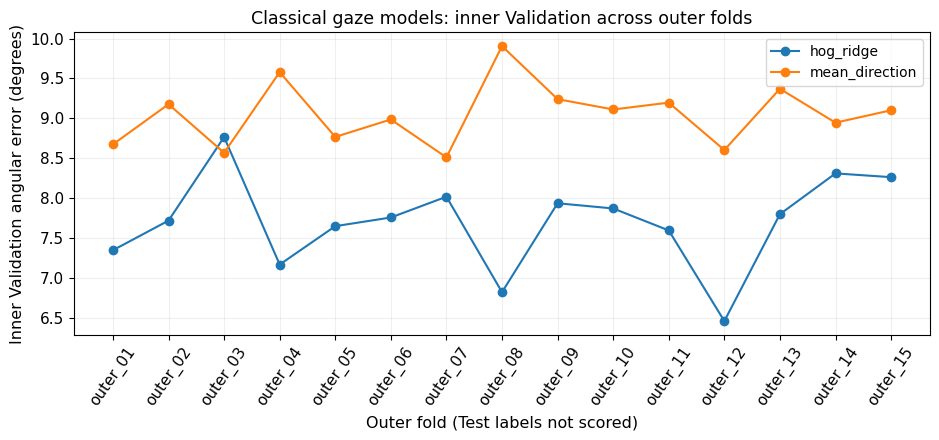

In [7]:
# =================== 06. Save Classical Modelling Evidence ===================

inner_validation.to_csv(
    out_dir / "03_inner_validation_metrics.csv", index=False)
configuration = selected[["fold_id", "model", "alpha"]].copy()
configuration = configuration.rename(columns={"alpha": "selected_alpha"})
configuration["run_mode"] = ("full_outer_lopo" if RUN_OUTER_TEST
                             else "development_inner_validation")
configuration["outer_fold_count"] = folds.fold_id.nunique()
configuration["test_used_for_selection"] = False
configuration.to_csv(out_dir / "03_run_configuration.csv", index=False)
fig, ax = plt.subplots(figsize=(9.5, 4.5))
for name, piece in selected.groupby("model"):
    ax.plot(piece.fold_id, piece.inner_val_mean_angular_error_deg,
            marker="o", label=name)
ax.set(title="Classical gaze models: inner Validation across outer folds",
       xlabel="Outer fold (Test labels not scored)",
       ylabel="Inner Validation angular error (degrees)")
ax.tick_params(axis="x", rotation=55)
ax.legend()
ax.grid(alpha=.2)
fig.tight_layout()
save_figure(fig, out_dir / "03_baseline_comparison.png")
plt.show()
if RUN_OUTER_TEST:
    outer_predictions.to_csv(
        out_dir / "03_baseline_outer_predictions.csv", index=False)
    per_person.to_csv(out_dir / "03_baseline_fold_metrics.csv", index=False)

**07. Interpretation and Output Download**

The classical development experiment establishes HOG + Ridge as a useful image-based comparator to the training-derived mean direction on this bounded cohort. Its improvement is descriptive and confined to inner Validation. All three development outputs are saved.

Notebook 04 develops the Small CNN and ResNet-18 on the same sample and role tables. Notebook 05 compares matched full outer-LOPO predictions only after the final procedures have been fixed and both model stages have produced the required evidence.

In [8]:
# ================ 07. Interpret Classical Results and Export =================

needed = ["03_inner_validation_metrics.csv",
          "03_run_configuration.csv", "03_baseline_comparison.png"]
if RUN_OUTER_TEST:
    needed += ["03_baseline_outer_predictions.csv",
               "03_baseline_fold_metrics.csv"]
missing = [x for x in needed if not (out_dir / x).is_file()]
if missing:
    raise FileNotFoundError(f"Stage-03 outputs missing: {missing}")
print("Inner Validation candidate/fold rows:", len(inner_validation))
print("Outer Test scored:", RUN_OUTER_TEST)
print("Next: 04_cnn_and_transfer_learning.ipynb")
(out_dir / "03_run_configuration.json").unlink(missing_ok=True)
download_outputs_from_colab("vision_based_gaze_estimation/output", "03")

Inner Validation candidate/fold rows: 60
Outer Test scored: False
Next: 04_cnn_and_transfer_learning.ipynb
------------------------------------------------------------------------
Notebook 03
Files packaged: 3
  + 03_baseline_comparison.png
  + 03_inner_validation_metrics.csv
  + 03_run_configuration.csv
Download ZIP from Colab Contents: /content/vision_based_gaze_estimation_Notebook_03_Outputs.zip
